# Arquetipos ofensivos de jugadores NBA — temporada 2025-26

Clasifica a cada jugador-temporada en **3 arquetipos ofensivos** y calcula su **afinidad** (probabilidad) con
cada uno. El resultado alimenta el dashboard de Power BI.

| Sección | Paso | Resultado |
| --- | --- | --- |
| 0–1 | Configuración y datos | Tablas de tiros, boxscore y partidos |
| 2–3 | Limpieza e inclusión | Tiros válidos; jugadores-temporada con 150 tiros o más |
| 4–6 | Variables | 5 zonas de tiro (proporciones) + 5 tasas por 36 minutos |
| 7 | Transformación | CLR para las zonas y estandarización |
| 8 | PCA | 4 componentes con significado táctico |
| 9 | Número de grupos | k = 3 (codo, silueta, estabilidad y BIC) |
| 10 | Modelo final | GMM con k = 3: arquetipo + afinidad |
| 11–13 | Interpretación | Perfiles, mapa y jugadores frontera |
| 14 | Exportación | CSV para Power BI |
| 15 | Decisiones | Alternativas probadas y por qué se descartaron |


## 0. Configuración

Todos los parámetros y constantes viven en esta celda.

In [1]:
import sys
from contextlib import closing
from pathlib import Path

RAIZ = Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

from src.db.connection import get_conn

# --- rutas
PARQUET_DIR = RAIZ / "src" / "data" / "parquet"
PARQUET_DIR.mkdir(parents=True, exist_ok=True)
ESQUEMA = "core"

# --- parámetros del análisis
TEMPORADAS = ["2025-26"]
MIN_FGA = 150            # tiros mínimos por jugador-temporada (sección 3)
N_COMP = 4               # componentes del PCA que entran al modelo (sección 8)
K = 3                    # número de arquetipos (sección 9)
UMBRAL_FRONTERA = 0.70   # afinidad mínima para que un jugador sea "Claro" (sección 13)
SEMILLA = 0

# --- zonas que la NBA clasifica como triple (para detectar incongruencias)
ZONAS_3PT = {"Above the Break 3", "Left Corner 3", "Right Corner 3", "Backcourt"}

# --- bloque de rol: tasas por 36 minutos
COLS_ROL = [
    "assists",
    "rebounds_offensive",
    "field_goals_attempted",
    "free_throws_attempted",
    "turnovers",
]

# --- nombres cortos para tablas y gráficos
ETIQ = {
    "Restricted Area": "Aro",
    "In The Paint (Non-RA)": "Pintura",
    "Mid-Range": "Media distancia",
    "Corner 3": "Triple esquina",
    "Above the Break 3": "Triple arco",
    "assists": "AST/36",
    "rebounds_offensive": "REB OF/36",
    "field_goals_attempted": "FGA/36",
    "free_throws_attempted": "FTA/36",
    "turnovers": "TOV/36",
}
ORDEN_ZONAS = ["Restricted Area", "In The Paint (Non-RA)", "Mid-Range", "Corner 3", "Above the Break 3"]

# --- arquetipos: descripción y color (los mismos en el notebook y en Power BI)
ARQUETIPOS = {
    "Creador con balón": (
        "Genera su tiro y el de otros: más tiros, asistencias y tiros libres.", "#d64541"),
    "Tirador de rol": (
        "Juega sin balón: espera el pase en el perímetro y pierde pocos balones.", "#2a78d6"),
    "Interior finalizador": (
        "Termina cerca del aro y genera segundas oportunidades con el rebote ofensivo.", "#8e5fc2"),
}
PALETA = {nombre: color for nombre, (_, color) in ARQUETIPOS.items()}
COL_AFIN = {
    "Creador con balón": "afin_creador",
    "Tirador de rol": "afin_tirador",
    "Interior finalizador": "afin_interior",
}

# --- jugadores conocidos para validar el modelo
CASOS_CONTROL = {
    201939: "Stephen Curry",
    201942: "DeMar DeRozan",
    203083: "Andre Drummond",
}

## 1. Datos

Las tablas se descargan de la base una sola vez y se guardan en `parquet`; después el notebook lee del disco.
`cargar_tabla` lee el parquet si existe y, si no, consulta la base, lo guarda y lo devuelve. Para forzar la
descarga, `refresh=True`.

In [87]:
def listar_tablas(esquema=ESQUEMA):
    """Nombres de las tablas del esquema. Consulta la base."""
    with closing(get_conn()) as conn:
        with conn.cursor() as cur:
            cur.execute(
                "SELECT table_name FROM information_schema.tables "
                "WHERE table_schema = %s ORDER BY table_name",
                (esquema,),
            )
            return [fila[0] for fila in cur.fetchall()]


def cargar_tabla(nombre, refresh=False, esquema=ESQUEMA):
    """Devuelve la tabla como DataFrame, leyendo del parquet local si ya existe."""
    ruta = PARQUET_DIR / f"{nombre}.parquet"
    if ruta.exists() and not refresh:
        return pd.read_parquet(ruta)

    with closing(get_conn()) as conn:
        df = pd.read_sql(f'SELECT * FROM {esquema}."{nombre}"', conn)
    df.to_parquet(ruta, engine="pyarrow", index=False)
    print(f"descargada {nombre}: {len(df):,} filas -> {ruta.name}")
    return df


def descargar_todo(refresh=False):
    """Baja todas las tablas del esquema. Solo tiene sentido con refresh=True."""
    for tabla in listar_tablas():
        cargar_tabla(tabla, refresh=refresh)

In [88]:
# descargar_todo(refresh=True)   # descomenta para refrescar los parquet desde la base

df_shots = cargar_tabla("fct_shots")
df_boxscore = cargar_tabla("fct_boxscore")
df_games = cargar_tabla("fct_games")

print(f"shots:    {df_shots.shape}")
print(f"boxscore: {df_boxscore.shape}")
print(f"games:    {df_games.shape}")

shots:    (467537, 29)
boxscore: (34587, 36)
games:    (2630, 33)


## 2. Limpieza de tiros

1. **Tiros incongruentes.** Un tiro marcado como triple en una zona de dos (o al revés) es un error de la
   fuente. Se detectan comparando `shot_type` con la lista de zonas de triple.
2. **Backcourt.** Lanzamientos desde media cancha al final del cuarto: circunstancia, no estilo.
3. **Esquinas unificadas.** El lado no define un estilo, y separarlas divide un volumen pequeño en dos.

Se usa `shot_zone_basic` (5 zonas). La versión con 13 zonas (`zone_id`) se descartó: las zonas pequeñas
metían ruido.

In [89]:
df_shots = df_shots[df_shots["season_num"].isin(TEMPORADAS)].copy()
print(f"tiros de {TEMPORADAS}: {len(df_shots):,}")

# 1. incongruencias entre el tipo de tiro y la zona
es_triple = df_shots["shot_type"] == "3PT Field Goal"
zona_de_triple = df_shots["shot_zone_basic"].isin(ZONAS_3PT)
incongruentes = es_triple != zona_de_triple
print(f"tiros incongruentes eliminados: {incongruentes.sum()}")
display(df_shots.loc[incongruentes, ["shot_type", "shot_zone_basic"]].value_counts())
df_shots = df_shots[~incongruentes]

# 2. backcourt
es_backcourt = df_shots["shot_zone_basic"] == "Backcourt"
print(f"tiros de backcourt eliminados: {es_backcourt.sum()}")
df_shots = df_shots[~es_backcourt].copy()

# 3. esquinas unificadas
df_shots["shot_zone_basic"] = df_shots["shot_zone_basic"].replace(
    {"Left Corner 3": "Corner 3", "Right Corner 3": "Corner 3"}
)

ZONAS = sorted(df_shots["shot_zone_basic"].unique())
assert set(ZONAS) == set(ORDEN_ZONAS), f"zonas inesperadas: {ZONAS}"
df_shots["shot_zone_basic"].value_counts()

tiros de ['2025-26']: 233,633
tiros incongruentes eliminados: 20


shot_type       shot_zone_basic  
2PT Field Goal  Above the Break 3    12
3PT Field Goal  Mid-Range             8
Name: count, dtype: int64

tiros de backcourt eliminados: 34


shot_zone_basic
Above the Break 3        71625
Restricted Area          66364
In The Paint (Non-RA)    46750
Corner 3                 25146
Mid-Range                23694
Name: count, dtype: int64

## 3. Criterio de inclusión

Con pocos tiros, las proporciones son ruido: si un jugador lanzó 20 veces y 4 fueron de esquina, ese 20 % no
dice nada. El corte en **150 tiros** sale del histograma: la distribución cae rápido y, por debajo, quedan sobre
todo jugadores de rotación corta.

El conteo es por **jugador y temporada**. Así, si se agrega otra temporada a `TEMPORADAS`, cada temporada
de un jugador se evalúa por separado y no se suman sus tiros.

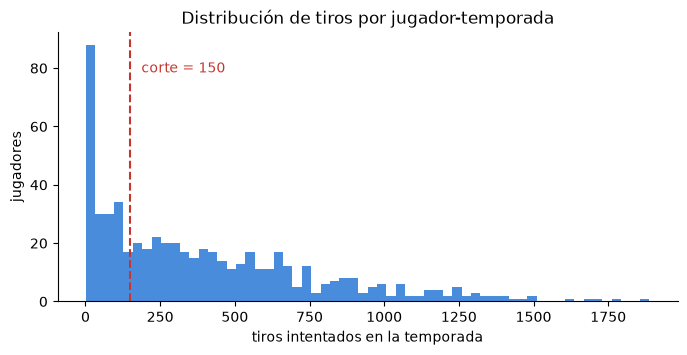

count     582.0
mean      401.3
std       374.3
min         1.0
25%        94.0
50%       301.5
75%       613.2
max      1888.0
Name: shot_attempted_flag, dtype: float64


In [90]:
fga = df_shots.groupby(["player_id", "season_num"])["shot_attempted_flag"].sum()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(fga, bins=60, color="#2a78d6", alpha=0.85)
ax.axvline(MIN_FGA, color="#C6362F", linestyle="--", linewidth=1.5)
ax.annotate(f"corte = {MIN_FGA}", xy=(MIN_FGA, ax.get_ylim()[1] * 0.85),
            xytext=(8, 0), textcoords="offset points", color="#C6362F", fontsize=10)
ax.set_xlabel("tiros intentados en la temporada")
ax.set_ylabel("jugadores")
ax.set_title("Distribución de tiros por jugador-temporada")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(fga.describe().round(1))

In [91]:
incluidos = fga[fga >= MIN_FGA].index
clave = pd.MultiIndex.from_frame(df_shots[["player_id", "season_num"]])
df_shots = df_shots[clave.isin(incluidos)].copy()

print(f"jugadores-temporada antes:   {len(fga)}")
print(f"jugadores-temporada después: {len(incluidos)}")

jugadores-temporada antes:   582
jugadores-temporada después: 387


## 4. Bloque A — perfil de tiro

Proporción de los tiros de cada jugador que sale de cada zona. Es una **composición**: las cinco columnas
suman 1.

- `fill_value=0`: un jugador que nunca tiró desde una zona tiene un 0, no un `NaN`.
- **Suavizado de Jeffreys** (+0.5 a cada zona): evita proporciones de cero, porque el CLR de la sección 7
  usa logaritmos.

In [92]:
conteos = (
    df_shots.groupby(["player_id", "season_num", "shot_zone_basic"])["shot_attempted_flag"].sum()
    .unstack(fill_value=0)
    .reindex(columns=ZONAS, fill_value=0)
)
conteos_suav = conteos + 0.5
df_perfil = conteos_suav.div(conteos_suav.sum(axis=1), axis=0)
df_perfil.columns.name = None

assert df_perfil.notna().all().all(), "hay NaN en el perfil de tiro"
assert np.allclose(df_perfil.sum(axis=1), 1), "hay filas que no suman 1"
print(f"{len(df_perfil)} jugadores-temporada x {len(ZONAS)} zonas")
df_perfil.head()

387 jugadores-temporada x 5 zonas


,,Above the Break 3,Corner 3,In The Paint (Non-RA),Mid-Range,Restricted Area
player_id,season_num,,,,,
2544,2025-26,0.216130,0.051201,0.206162,0.169008,0.357499
201142,2025-26,0.291622,0.035599,0.275800,0.304567,0.092413
201143,2025-26,0.482389,0.148545,0.176110,0.050536,0.142420
201144,2025-26,0.534247,0.221135,0.127202,0.045010,0.072407
201566,2025-26,0.322638,0.128936,0.209745,0.138443,0.200238


## 5. Bloque B — rol por 36 minutos

Dividir por minutos separa **estilo** de **oportunidad**: un titular y un suplente con el mismo juego tendrían
totales muy distintos. El `× 36` solo facilita la lectura; al estandarizar desaparece.

Los triples intentados por 36 (3PA) no se usan: repiten información que ya está en el perfil de tiro.

In [93]:
def minutos_a_decimal(texto):
    """'45:15' -> 45.25"""
    mm, ss = texto.split(":")
    return int(mm) + int(ss) / 60


df_box = df_boxscore[["game_id", "person_id", "minutes"] + COLS_ROL].copy()

# los partidos sin jugar (DNP) vienen con minutos vacíos
es_dnp = df_box["minutes"] == ""
print(f"filas sin minutos (DNP) eliminadas: {es_dnp.sum():,}")
df_box = df_box[~es_dnp].copy()
df_box["minutes"] = df_box["minutes"].apply(minutos_a_decimal)

# temporada de cada partido
partidos = df_games[["game_id", "season_num"]].drop_duplicates()
assert partidos["game_id"].is_unique, "hay game_id con más de una temporada"
df_box = df_box.merge(partidos, how="left", on="game_id", validate="many_to_one")
print(f"filas de boxscore sin temporada: {df_box['season_num'].isna().sum():,}")
df_box = df_box[df_box["season_num"].isin(TEMPORADAS)]

df_rol = (
    df_box.rename(columns={"person_id": "player_id"})
    .groupby(["player_id", "season_num"])
    .agg(minutes=("minutes", "sum"),
         partidos=("game_id", "nunique"),
         **{col: (col, "sum") for col in COLS_ROL})
)
df_rol[COLS_ROL] = df_rol[COLS_ROL].div(df_rol["minutes"], axis=0) * 36
df_rol.head()

filas sin minutos (DNP) eliminadas: 6,015
filas de boxscore sin temporada: 0


,,minutes,partidos,assists,rebounds_offensive,field_goals_attempted,free_throws_attempted,turnovers
player_id,season_num,,,,,,,
2544,2025-26,2372.866667,70,7.661619,0.713062,16.719018,5.750007,3.292220
101108,2025-26,227.533333,16,8.385585,0.949311,8.860240,0.316437,2.531497
200768,2025-26,120.816667,16,3.277693,0.000000,7.449303,1.787833,1.191889
201142,2025-26,2880.816667,79,4.698668,0.537348,17.345082,5.948313,3.186596
201143,2025-26,969.200000,45,4.308708,1.634338,12.034668,0.965745,1.560050


## 6. Matriz de variables

`validate="one_to_one"` hace que el merge falle si hay jugadores duplicados, en vez de multiplicar filas en
silencio. Los minutos y los partidos solo sirven de control de calidad: no entran al modelo.

In [94]:
df_features = df_perfil.merge(df_rol, how="left", left_index=True, right_index=True,
                              validate="one_to_one")

sin_box = df_features[COLS_ROL].isna().any(axis=1)
print(f"jugadores sin datos de boxscore: {sin_box.sum()}")
assert not sin_box.any(), "hay jugadores con tiros pero sin boxscore"

print(df_features[["minutes", "partidos"]].describe().round(1))
print(f"\nmáximo de partidos: {df_features['partidos'].max()} "
      "(más de 82 indica que el boxscore incluye playoffs o play-in)")

jugadores sin datos de boxscore: 0
       minutes  partidos
count    387.0     387.0
mean    1539.9      64.4
std      691.1      17.8
min      338.7      14.0
25%      972.7      53.0
50%     1446.7      67.0
75%     2012.2      78.0
max     3300.2     105.0

máximo de partidos: 105 (más de 82 indica que el boxscore incluye playoffs o play-in)


In [95]:
COLS_FEATURES = ZONAS + COLS_ROL
df_features = df_features[COLS_FEATURES]

df_features.reset_index().to_parquet(PARQUET_DIR / "features_player_season.parquet",
                                     engine="pyarrow", index=False)
print(f"matriz: {len(df_features)} jugadores x {len(COLS_FEATURES)} variables "
      "-> features_player_season.parquet")
df_features.describe().T.round(2)

matriz: 387 jugadores x 10 variables -> features_player_season.parquet


,count,mean,std,min,25%,50%,75%,max
Above the Break 3,387.0,0.30,0.15,0.00,0.21,0.31,0.41,0.67
Corner 3,387.0,0.12,0.08,0.00,0.06,0.11,0.18,0.46
In The Paint (Non-RA),387.0,0.19,0.09,0.01,0.13,0.18,0.24,0.57
Mid-Range,387.0,0.09,0.07,0.00,0.03,0.07,0.12,0.48
Restricted Area,387.0,0.30,0.17,0.01,0.18,0.26,0.37,0.98
assists,387.0,3.90,2.04,0.82,2.33,3.38,4.93,11.26
rebounds_offensive,387.0,1.69,1.22,0.20,0.83,1.29,2.12,7.55
field_goals_attempted,387.0,13.15,3.50,5.05,10.61,12.88,15.42,22.92
free_throws_attempted,387.0,3.36,1.95,0.31,1.88,2.99,4.30,12.37
turnovers,387.0,2.05,0.78,0.54,1.51,1.88,2.49,4.50


## 7. CLR y estandarización

- **CLR** (*centered log-ratio*): compara cada zona con el promedio geométrico de las zonas del jugador, en
  escala logarítmica. Corrige que las proporciones dependan unas de otras y que duplicar un 2 % pese menos que
  sumar 2 puntos a un 40 %.
- **Estandarización**: lleva cada variable a media 0 y desviación 1 para que todas pesen igual en las
  distancias.

Las 5 columnas CLR de cada jugador suman 0; por eso el último componente del PCA explica 0 % de la varianza.

In [96]:
X = df_features[ZONAS].to_numpy()
X_clr = np.log(X / np.exp(np.log(X).mean(axis=1, keepdims=True)))

df_modelo = pd.DataFrame(X_clr, columns=[f"clr_{z}" for z in ZONAS], index=df_features.index)
df_modelo[COLS_ROL] = df_features[COLS_ROL]

X_norm = StandardScaler().fit_transform(df_modelo)
print(f"matriz del modelo: {X_norm.shape[0]} jugadores x {X_norm.shape[1]} variables")

matriz del modelo: 387 jugadores x 10 variables


## 8. PCA

Resume las 10 variables en pocos ejes. Entran al modelo los `N_COMP` primeros: el resto aporta poca varianza y
no tiene lectura clara.

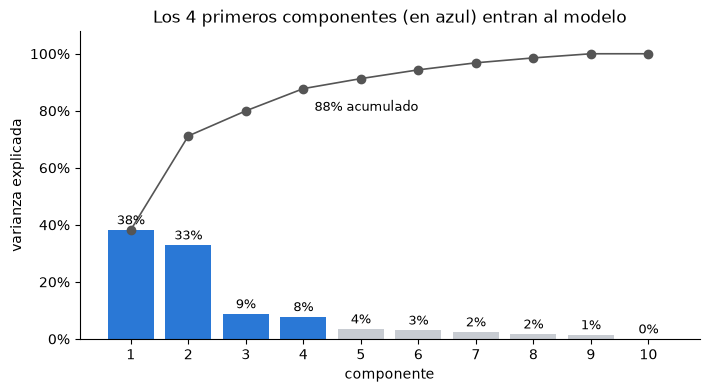

In [97]:
pca = PCA().fit(X_norm)
num_comp = [f"PCA{i + 1}" for i in range(pca.n_components_)]
var_exp = pca.explained_variance_ratio_

df_pca = pd.DataFrame(pca.components_, columns=df_modelo.columns, index=num_comp)
df_proyecciones = pd.DataFrame(pca.transform(X_norm), columns=num_comp,
                               index=df_modelo.index)[num_comp[:N_COMP]]

# --- varianza explicada (scree)
x = np.arange(1, len(var_exp) + 1)
acum = var_exp.cumsum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x, var_exp, color=["#2a78d6" if i <= N_COMP else "#c8ccd2" for i in x])
ax.plot(x, acum, marker="o", color="#555555", linewidth=1.2)
for xi, v in zip(x, var_exp):
    ax.annotate(f"{v:.0%}", (xi, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax.annotate(f"{acum[N_COMP - 1]:.0%} acumulado", (N_COMP, acum[N_COMP - 1]),
            xytext=(8, -16), textcoords="offset points", fontsize=9)
ax.set_xticks(x)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("componente")
ax.set_ylabel("varianza explicada")
ax.set_title(f"Los {N_COMP} primeros componentes (en azul) entran al modelo")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 8.1 Signo e interpretación de los componentes

El signo de un componente es arbitrario (PC1 y −PC1 tienen la misma información). Cada eje se orienta con una
**variable ancla** que siempre queda positiva, para que la interpretación no se invierta entre ejecuciones.

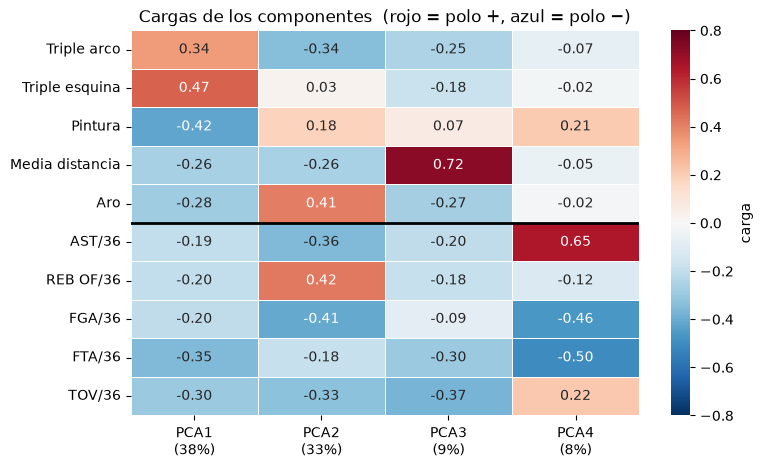

In [98]:
ANCLAS = {
    "PCA1": "clr_Corner 3",          # +  tirador exterior
    "PCA2": "clr_Restricted Area",   # +  finalizador interior
    "PCA3": "clr_Mid-Range",         # +  media distancia
    "PCA4": "assists",               # +  pasador
}
for pc, ancla in ANCLAS.items():
    if df_pca.loc[pc, ancla] < 0:
        df_pca.loc[pc] *= -1
        if pc in df_proyecciones.columns:
            df_proyecciones[pc] *= -1

# --- mapa de cargas de los componentes que entran al modelo
cargas = df_pca.loc[num_comp[:N_COMP]].T
cargas.index = [ETIQ.get(c.replace("clr_", ""), c) for c in cargas.index]
cargas.columns = [f"{pc}\n({v:.0%})" for pc, v in zip(cargas.columns, var_exp)]

fig, ax = plt.subplots(figsize=(1.3 * N_COMP + 3, 5))
sns.heatmap(cargas, cmap="RdBu_r", center=0, vmin=-0.8, vmax=0.8,
            annot=True, fmt=".2f", linewidths=0.5, cbar_kws={"label": "carga"}, ax=ax)
ax.axhline(len(ZONAS), color="black", lw=2)   # separa perfil de tiro / rol
ax.set_title("Cargas de los componentes  (rojo = polo +, azul = polo −)")
ax.set_xlabel("")
plt.show()

| Componente | Varianza | Polo + | Polo − | Lectura |
| --- | --- | --- | --- | --- |
| PC1 | 38 % | Triple esquina, triple arco | Pintura, FTA, TOV, aro | **Tirador exterior de bajo uso ↔ jugador interior o con uso** |
| PC2 | 33 % | Rebote ofensivo, aro | FGA, AST, triple arco, TOV | **Finalizador interior ↔ creador con balón** |
| PC3 | 9 % | Media distancia | TOV, FTA, aro | **Especialista de media distancia** que no ataca el aro |
| PC4 | 8 % | Asistencias | FTA, FGA | **Pasador puro**: reparte sin buscar su tiro |

Los porcentajes son los de la ejecución de 2025-26. Si cambian los datos, revisa que el mapa de cargas siga
diciendo lo mismo.

**Control con jugadores conocidos:** Curry debe quedar en el polo creador de PC2 (negativo) y DeRozan en el polo
de media distancia de PC3 (positivo).

In [99]:
ids_modelo = df_proyecciones.index.get_level_values("player_id")
casos = [i for i in CASOS_CONTROL if i in ids_modelo]
df_proyecciones.loc[casos].rename(index=CASOS_CONTROL, level="player_id").round(2)

,,PCA1,PCA2,PCA3,PCA4
player_id,season_num,,,,
Stephen Curry,2025-26,-1.22,-3.40,-0.56,-1.05
DeMar DeRozan,2025-26,-1.53,-1.41,2.35,-0.77
Andre Drummond,2025-26,0.10,3.84,-1.46,-0.02


## 9. Número de grupos

Ningún algoritmo de clustering elige k por sí solo. Se usan cuatro pruebas independientes:

| Prueba | Qué mide | Cómo se lee |
| --- | --- | --- |
| Inercia (codo) | Distancia total de cada jugador a su centro | Siempre baja; se busca dónde deja de bajar rápido |
| Silueta | Si cada jugador está más cerca de su grupo que del vecino (−1 a 1) | Más de 0.25: hay estructura |
| Estabilidad (ARI) | Si con submuestras del 80 % sale la misma partición (0 a 1) | Más de 0.75: sólida; menos de 0.5: ruido |
| BIC (GMM) | Ajuste del modelo, castigando la complejidad | Gana el k con el BIC más bajo |

La estabilidad se mide para los dos modelos candidatos: K-Means y GMM. Esta celda tarda unos minutos.

In [100]:
def estabilidad(X, k, modelo="kmeans", n_rep=50, frac=0.8, seed=SEMILLA):
    """ARI medio y desviación entre particiones hechas sobre submuestras del 80 %."""
    rng = np.random.default_rng(seed)
    etiquetas = []
    for _ in range(n_rep):
        idx = rng.choice(len(X), size=int(len(X) * frac), replace=False)
        sub = X.iloc[idx]
        if modelo == "kmeans":
            lab_sub = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(sub)
        else:
            lab_sub = GaussianMixture(n_components=k, covariance_type="full",
                                      n_init=5, random_state=0).fit(sub).predict(sub)
        lab = np.full(len(X), -1)          # -1 = el jugador no entró en esta repetición
        lab[idx] = lab_sub
        etiquetas.append(lab)

    aris = []
    for i in range(n_rep):
        for j in range(i + 1, n_rep):
            comun = (etiquetas[i] >= 0) & (etiquetas[j] >= 0)
            aris.append(adjusted_rand_score(etiquetas[i][comun], etiquetas[j][comun]))
    return np.mean(aris), np.std(aris)


inercias = {k: KMeans(n_clusters=k, n_init=25, random_state=SEMILLA).fit(df_proyecciones).inertia_
            for k in range(1, 11)}

filas = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=25, random_state=SEMILLA).fit(df_proyecciones)
    gm = GaussianMixture(n_components=k, covariance_type="full",
                         n_init=5, random_state=SEMILLA).fit(df_proyecciones)
    ari_km, sd_km = estabilidad(df_proyecciones, k, "kmeans")
    ari_gm, sd_gm = estabilidad(df_proyecciones, k, "gmm")
    filas.append({
        "k": k,
        "silueta": silhouette_score(df_proyecciones, km.labels_),
        "ARI K-Means": ari_km, "± K-Means": sd_km,
        "ARI GMM": ari_gm, "± GMM": sd_gm,
        "BIC": gm.bic(df_proyecciones),
    })
tabla_k = pd.DataFrame(filas).set_index("k")
tabla_k.round({"silueta": 2, "ARI K-Means": 2, "± K-Means": 2, "ARI GMM": 2, "± GMM": 2, "BIC": 0})

,silueta,ARI K-Means,± K-Means,ARI GMM,± GMM,BIC
k,,,,,,
2,0.32,0.52,0.41,0.60,0.31,5026.0
3,0.35,0.95,0.04,0.85,0.07,4974.0
4,0.26,0.73,0.22,0.55,0.14,5021.0
5,0.24,0.81,0.10,0.48,0.12,5078.0
6,0.24,0.62,0.12,0.44,0.10,5159.0


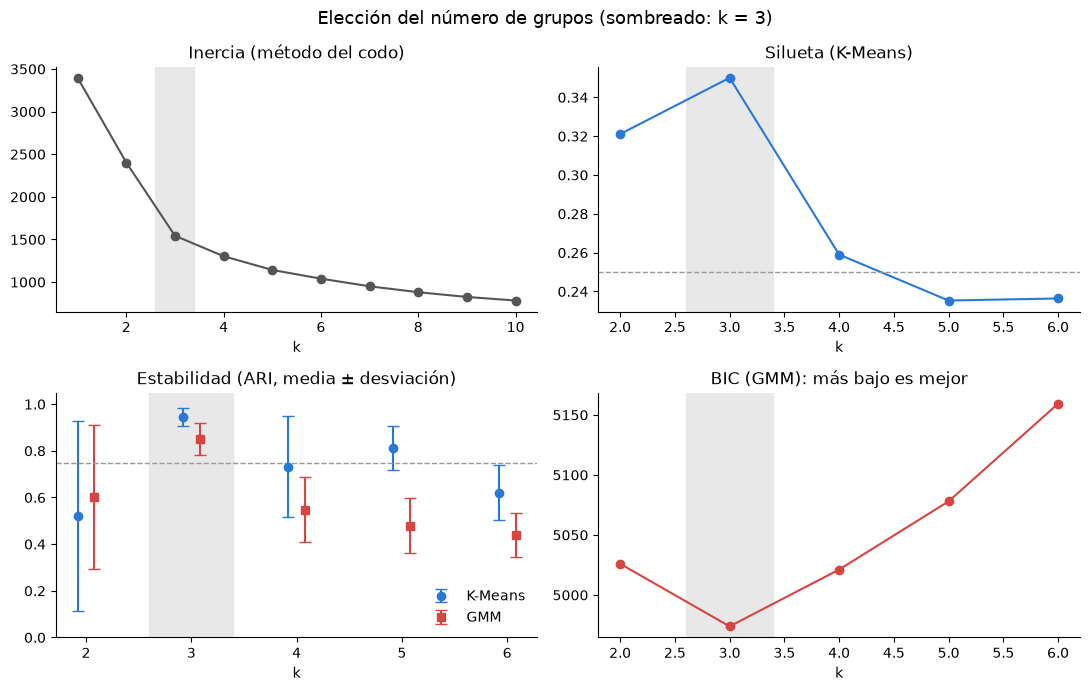

In [101]:
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
ks = tabla_k.index


def marcar_k(ax):
    ax.axvspan(K - 0.4, K + 0.4, color="#e8e8e8", zorder=0)
    ax.spines[["top", "right"]].set_visible(False)


ax = axs[0, 0]
ax.plot(list(inercias), list(inercias.values()), marker="o", color="#555555")
ax.set_title("Inercia (método del codo)")
ax.set_xlabel("k")
marcar_k(ax)

ax = axs[0, 1]
ax.plot(ks, tabla_k["silueta"], marker="o", color="#2a78d6")
ax.axhline(0.25, color="#999999", linestyle="--", linewidth=1)
ax.set_title("Silueta (K-Means)")
ax.set_xlabel("k")
marcar_k(ax)

ax = axs[1, 0]
ax.errorbar(ks - 0.08, tabla_k["ARI K-Means"], yerr=tabla_k["± K-Means"], fmt="o", capsize=4,
            color="#2a78d6", label="K-Means")
ax.errorbar(ks + 0.08, tabla_k["ARI GMM"], yerr=tabla_k["± GMM"], fmt="s", capsize=4,
            color="#d64541", label="GMM")
ax.axhline(0.75, color="#999999", linestyle="--", linewidth=1)
ax.set_ylim(0, 1.05)
ax.set_title("Estabilidad (ARI, media ± desviación)")
ax.set_xlabel("k")
ax.legend(frameon=False)
marcar_k(ax)

ax = axs[1, 1]
ax.plot(ks, tabla_k["BIC"], marker="o", color="#d64541")
ax.set_title("BIC (GMM): más bajo es mejor")
ax.set_xlabel("k")
marcar_k(ax)

fig.suptitle(f"Elección del número de grupos (sombreado: k = {K})", fontsize=13)
fig.tight_layout()
plt.show()

**Conclusión: k = 3.** En la ejecución de 2025-26 las pruebas coinciden:

- El codo está en k = 3.
- La silueta es máxima en k = 3 (0.35).
- K-Means es más estable con k = 3 (ARI 0.95 ± 0.04), y el GMM también es estable (0.85 ± 0.07).
- El BIC tiene su mínimo en k = 3.

Con k = 5 el GMM se vuelve inestable (ARI 0.48), y K-Means queda aceptable (0.81) pero con fronteras difusas.

## 10. Modelo final: GMM con k = 3

**Por qué GMM y no K-Means.**

- **Etiqueta y afinidad salen del mismo modelo.** El GMM da la probabilidad de pertenecer a cada arquetipo, así
  que la etiqueta (el arquetipo más probable) y la afinidad son coherentes. Con K-Means la afinidad tendría que
  venir de otro modelo, y a veces lo contradice.
- **Es estable** (ARI 0.85 con k = 3).
- **La afinidad es informativa:** en 2025-26, un 34 % de los jugadores tiene menos de 0.9 en su arquetipo
  principal.
- **Clasifica mejor a los organizadores de bajo uso.** K-Means ponía a jugadores como Lonzo Ball o Mike Conley
  entre los tiradores de rol (tiran poco y desde el perímetro); el GMM los ubica como creadores.

**Cómo se nombran los grupos.** Los números de cluster cambian entre ejecuciones, así que el nombre se asigna
por regla: el grupo con más tiros en el aro es *Interior finalizador*; de los restantes, el de más asistencias
es *Creador con balón*; el que queda es *Tirador de rol*.

In [102]:
gmm = GaussianMixture(n_components=K, covariance_type="full",
                      n_init=10, random_state=SEMILLA).fit(df_proyecciones)
prob = gmm.predict_proba(df_proyecciones)

df_res = df_features.copy()
df_res["cluster"] = prob.argmax(axis=1)

# --- nombres por regla
assert K == 3, "la regla de nombres está pensada para 3 arquetipos"
medias_c = df_res.groupby("cluster")[COLS_FEATURES].mean()
interior = medias_c["Restricted Area"].idxmax()
creador = medias_c.drop(index=interior)["assists"].idxmax()
NOMBRES = {c: "Tirador de rol" for c in medias_c.index}
NOMBRES[interior] = "Interior finalizador"
NOMBRES[creador] = "Creador con balón"
df_res["arquetipo"] = df_res["cluster"].map(NOMBRES)

# --- afinidad con cada arquetipo, arquetipo secundario y encaje
for c, nombre in NOMBRES.items():
    df_res[COL_AFIN[nombre]] = prob[:, c]
df_res["afinidad"] = prob.max(axis=1)
df_res["arquetipo_secundario"] = pd.Series(np.argsort(prob, axis=1)[:, -2],
                                           index=df_res.index).map(NOMBRES)
df_res["encaje"] = np.where(df_res["afinidad"] >= UMBRAL_FRONTERA, "Claro", "Frontera")

print(f"silueta de la partición: {silhouette_score(df_proyecciones, df_res['cluster']):.2f}")
km_ref = KMeans(n_clusters=K, n_init=25, random_state=SEMILLA).fit(df_proyecciones)
print(f"coincidencia con K-Means k={K} (ARI): {adjusted_rand_score(km_ref.labels_, df_res['cluster']):.2f}")
display(df_res["arquetipo"].value_counts().rename("jugadores"))

print("\njugadores según su afinidad con el arquetipo principal:")
print(pd.cut(df_res["afinidad"], [0, 0.6, 0.7, 0.8, 0.9, 0.99, 1.0]).value_counts().sort_index())

silueta de la partición: 0.30
coincidencia con K-Means k=3 (ARI): 0.64


arquetipo
Tirador de rol          193
Creador con balón       148
Interior finalizador     46
Name: jugadores, dtype: int64


jugadores según su afinidad con el arquetipo principal:
afinidad
(0.0, 0.6]      25
(0.6, 0.7]      26
(0.7, 0.8]      31
(0.8, 0.9]      51
(0.9, 0.99]    132
(0.99, 1.0]    122
Name: count, dtype: int64


## 11. Perfil de cada arquetipo

En el heatmap, cada celda muestra el **valor real** del arquetipo y el color indica cuánto se aleja de la media
de la liga (**z-score**): rojo por encima, azul por debajo.

In [103]:
def perfil_grupos(df, col_grupo, ref=None):
    """Media de cada variable por grupo, en unidades reales y en z respecto a `ref`."""
    ref = df if ref is None else ref
    medias = df.groupby(col_grupo)[COLS_FEATURES].mean()
    z = (medias - ref[COLS_FEATURES].mean()) / ref[COLS_FEATURES].std()
    return medias, z


def rasgos(z, n=3):
    """Las n variables que más distinguen a cada grupo (↑ por encima, ↓ por debajo)."""
    out = {}
    for g, fila in z.iterrows():
        top = fila.reindex(fila.abs().sort_values(ascending=False).index).head(n)
        out[g] = ",  ".join(f"{'↑' if v > 0 else '↓'} {ETIQ.get(c, c)}" for c, v in top.items())
    return pd.Series(out, name="rasgos")


def heatmap_perfil(medias, z, titulo, etiqueta_z="z vs. liga"):
    """Celdas = valor real; color = z. Zonas en %, tasas por 36 con un decimal."""
    texto = pd.DataFrame({c: medias[c].map(lambda v, c=c: f"{v:.0%}" if c in ZONAS else f"{v:.1f}")
                          for c in medias.columns})
    filas = ORDEN_ZONAS + COLS_ROL
    fig, ax = plt.subplots(figsize=(1.9 * len(medias) + 3, 5))
    sns.heatmap(z[filas].T.rename(index=ETIQ), cmap="RdBu_r", center=0, vmin=-2, vmax=2,
                annot=texto[filas].T.values, fmt="", linewidths=0.5,
                cbar_kws={"label": etiqueta_z}, ax=ax)
    ax.axhline(len(ZONAS), color="black", lw=2)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=0)
    plt.show()


def nombres_jugadores(df_box):
    """Busca en el boxscore una columna de nombre; si no hay, devuelve una serie vacía."""
    cols = [c for c in df_box.columns if "name" in c.lower() and "team" not in c.lower()]
    if {"first_name", "family_name"} <= set(cols):
        s = df_box["first_name"].str.cat(df_box["family_name"], sep=" ")
    elif cols:
        s = df_box[cols[0]].astype(str)
    else:
        return pd.Series(dtype=str)
    return s.groupby(df_box["person_id"]).first()


ids = df_res.index.get_level_values("player_id")
df_res["nombre"] = (nombres_jugadores(df_boxscore).reindex(ids)
                    .fillna(pd.Series(ids.astype(str), index=ids)).values)

,jugadores,silueta,rasgos
Tirador de rol,193,0.37,"↑ Triple esquina, ↓ TOV/36, ↓ AST/36"
Creador con balón,148,0.22,"↑ AST/36, ↑ TOV/36, ↑ FGA/36"
Interior finalizador,46,0.30,"↑ Aro, ↑ REB OF/36, ↓ Triple arco"


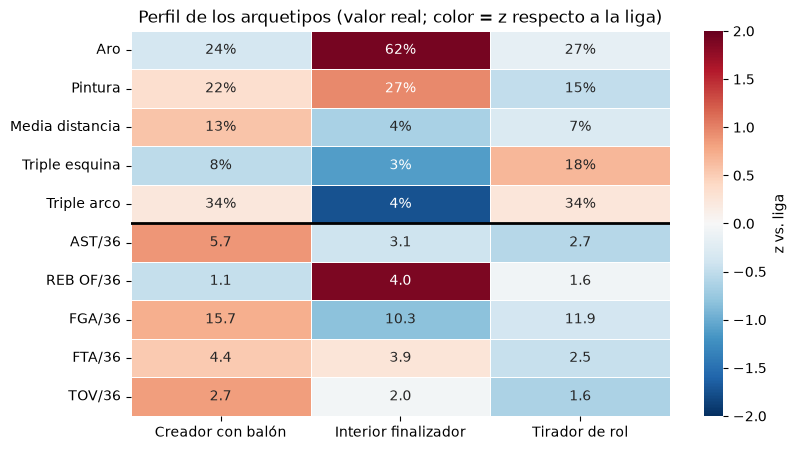

In [104]:
medias, z = perfil_grupos(df_res, "arquetipo")
sil = pd.Series(silhouette_samples(df_proyecciones, df_res["cluster"]), index=df_res.index)

resumen = pd.concat([
    df_res["arquetipo"].value_counts().rename("jugadores"),
    sil.groupby(df_res["arquetipo"]).mean().round(2).rename("silueta"),
    rasgos(z),
], axis=1)
display(resumen)

heatmap_perfil(medias, z, "Perfil de los arquetipos (valor real; color = z respecto a la liga)")

In [105]:
# --- jugadores representativos: los más cercanos al centro de su arquetipo en el espacio del PCA
centro = gmm.means_[df_res["cluster"].to_numpy()]
df_res["dist_centro"] = np.linalg.norm(df_proyecciones.to_numpy() - centro, axis=1)

representativos = (
    df_res.sort_values("dist_centro")
    .groupby("arquetipo").head(5)
    .sort_values(["arquetipo", "dist_centro"])
)
representativos[["arquetipo", "nombre", "afinidad", "dist_centro"]].round(2)

,,arquetipo,nombre,afinidad,dist_centro
player_id,season_num,,,,
1642273,2025-26,Creador con balón,Kyshawn George,0.99,0.61
1630703,2025-26,Creador con balón,Scoot Henderson,0.99,0.64
1642450,2025-26,Creador con balón,Daniss Jenkins,0.98,0.69
1628368,2025-26,Creador con balón,De'Aaron Fox,1.00,0.71
1642847,2025-26,Creador con balón,Jeremiah Fears,0.98,0.73
1630543,2025-26,Interior finalizador,Isaiah Jackson,1.00,0.95
1641709,2025-26,Interior finalizador,Ausar Thompson,1.00,1.12
203497,2025-26,Interior finalizador,Rudy Gobert,1.00,1.24
1629674,2025-26,Interior finalizador,Neemias Queta,1.00,1.25


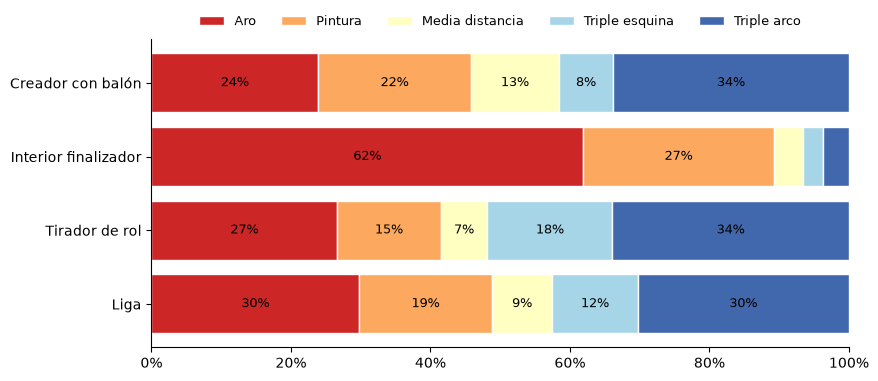

In [106]:
# --- de dónde tira cada arquetipo, frente a la liga
dist = medias[ORDEN_ZONAS].copy()
dist.loc["Liga"] = df_res[ORDEN_ZONAS].mean()
dist = dist.div(dist.sum(axis=1), axis=0)

colores = plt.cm.RdYlBu(np.linspace(0.08, 0.92, len(ORDEN_ZONAS)))
fig, ax = plt.subplots(figsize=(9, 0.7 * len(dist) + 1.2))
izq = np.zeros(len(dist))
for zona, color in zip(ORDEN_ZONAS, colores):
    ax.barh(dist.index, dist[zona], left=izq, color=color, edgecolor="white", label=ETIQ[zona])
    for i, (x0, w) in enumerate(zip(izq, dist[zona])):
        if w >= 0.06:
            ax.text(x0 + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=9)
    izq += dist[zona].to_numpy()

ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(ncol=len(ORDEN_ZONAS), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 12. Mapa de arquetipos

PC1 contra PC2 (71 % de la varianza): ejes con significado, distancias reales y el mismo espacio en el que
trabaja el modelo. La **transparencia** es la afinidad: los puntos tenues son jugadores frontera. Se rotulan los
2 jugadores más representativos de cada arquetipo.

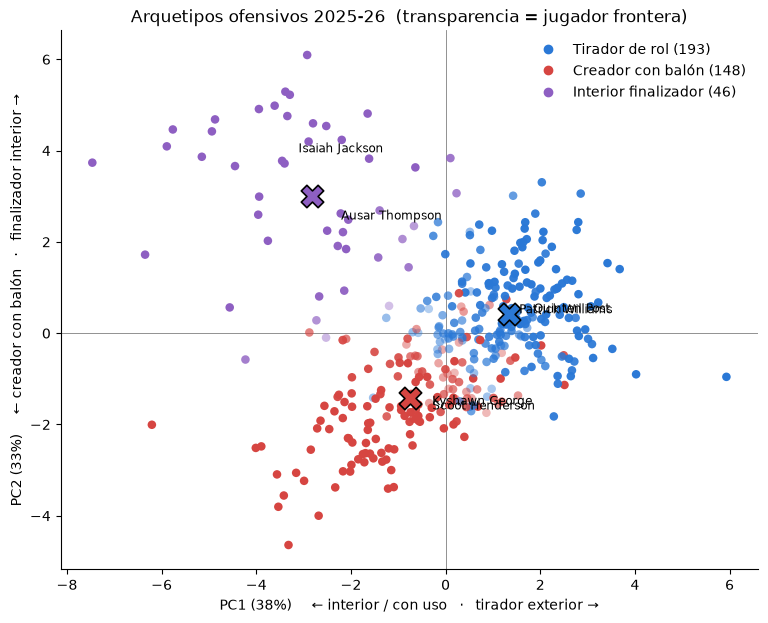

In [107]:
rgba = np.array([to_rgba(PALETA[a]) for a in df_res["arquetipo"]])
escala = np.clip((df_res["afinidad"].to_numpy() - 1 / K) / (1 - 1 / K), 0, 1)
rgba[:, 3] = 0.15 + 0.85 * escala        # afinidad 1/K -> casi transparente, 1 -> opaco

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(df_proyecciones["PCA1"], df_proyecciones["PCA2"], c=rgba, s=38, edgecolor="none")

for c, nombre in NOMBRES.items():
    ax.scatter(gmm.means_[c, 0], gmm.means_[c, 1], marker="X", s=260, color=PALETA[nombre],
               edgecolor="black", linewidth=1.2, zorder=3)

for _, fila in representativos.groupby("arquetipo").head(2).iterrows():
    x0, y0 = df_proyecciones.loc[fila.name, ["PCA1", "PCA2"]]
    ax.annotate(fila["nombre"], (x0, y0), xytext=(10, 8), textcoords="offset points", fontsize=8.5)

ax.axhline(0, color="grey", lw=0.6, zorder=0)
ax.axvline(0, color="grey", lw=0.6, zorder=0)
ax.set_xlabel(f"PC1 ({var_exp[0]:.0%})     ← interior / con uso   ·   tirador exterior →")
ax.set_ylabel(f"PC2 ({var_exp[1]:.0%})     ← creador con balón   ·   finalizador interior →")
ax.set_title(f"Arquetipos ofensivos {', '.join(TEMPORADAS)}  (transparencia = jugador frontera)")
handles = [Line2D([], [], marker="o", ls="", color=PALETA[a], label=f"{a} ({n})")
           for a, n in df_res["arquetipo"].value_counts().items()]
ax.legend(handles=handles, loc="best", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 13. Jugadores frontera

Un jugador es **frontera** si su afinidad con el arquetipo principal es menor que `UMBRAL_FRONTERA` (0.70):
comparte rasgos con un segundo arquetipo. No es un error del modelo; los estilos de juego son un continuo.

In [108]:
display(df_res["encaje"].value_counts().rename("jugadores"))

frontera = df_res[df_res["encaje"] == "Frontera"]
display(pd.crosstab(frontera["arquetipo"], frontera["arquetipo_secundario"],
                    rownames=["arquetipo"], colnames=["arquetipo secundario"]))

frontera.sort_values("afinidad")[["nombre", "arquetipo", "arquetipo_secundario", "afinidad"]].head(15).round(2)

encaje
Claro       336
Frontera     51
Name: jugadores, dtype: int64

arquetipo secundario,Creador con balón,Interior finalizador,Tirador de rol
arquetipo,,,
Creador con balón,0,0,22
Interior finalizador,2,0,1
Tirador de rol,24,2,0


,,nombre,arquetipo,arquetipo_secundario,afinidad
player_id,season_num,,,,
1629021,2025-26,Moritz Wagner,Tirador de rol,Creador con balón,0.50
1642263,2025-26,Reed Sheppard,Creador con balón,Tirador de rol,0.51
1630530,2025-26,Trey Murphy III,Creador con balón,Tirador de rol,0.51
203932,2025-26,Aaron Gordon,Tirador de rol,Creador con balón,0.51
1630570,2025-26,Trendon Watford,Interior finalizador,Creador con balón,0.52
203935,2025-26,Marcus Smart,Creador con balón,Tirador de rol,0.52
203992,2025-26,Bogdan Bogdanović,Tirador de rol,Creador con balón,0.53
202696,2025-26,Nikola Vučević,Tirador de rol,Creador con balón,0.54
1628997,2025-26,Caleb Martin,Tirador de rol,Creador con balón,0.54


In [109]:
# --- casos conocidos: su afinidad con cada arquetipo
casos = [i for i in CASOS_CONTROL if i in ids]
df_res.loc[casos, ["nombre", "arquetipo", "encaje"] + list(COL_AFIN.values())].round(2)

,,nombre,arquetipo,encaje,afin_creador,afin_tirador,afin_interior
player_id,season_num,,,,,,
201939,2025-26,Stephen Curry,Creador con balón,Claro,1.00,0.00,0.00
201942,2025-26,DeMar DeRozan,Tirador de rol,Frontera,0.42,0.58,0.00
203083,2025-26,Andre Drummond,Interior finalizador,Claro,0.00,0.12,0.88


## 14. Exportación para Power BI

Dos archivos en `PARQUET_DIR`:

| Archivo | Contenido | Relación en Power BI |
| --- | --- | --- |
| `pbi_arquetipos_jugadores.csv` | Un jugador-temporada por fila: arquetipo, las 3 afinidades, encaje, arquetipo secundario, los 2 ejes del mapa, las 5 zonas y las 5 tasas por 36 | Con la dimensión de jugadores por `player_id` |
| `pbi_arquetipos.csv` | Arquetipo, descripción y color | Con la tabla anterior por `arquetipo` |

`utf-8-sig` hace que Power BI lea bien las tildes. La afinidad se muestra mejor como barra apilada al 100 % con
las tres columnas `afinidad_*`.

In [110]:
export = pd.DataFrame({
    "player_id": df_res.index.get_level_values("player_id"),
    "temporada": df_res.index.get_level_values("season_num"),
    "jugador": df_res["nombre"].values,
    "arquetipo": df_res["arquetipo"].values,
    "afinidad_creador": df_res["afin_creador"].round(3).values,
    "afinidad_tirador": df_res["afin_tirador"].round(3).values,
    "afinidad_interior": df_res["afin_interior"].round(3).values,
    "encaje": df_res["encaje"].values,
    "arquetipo_secundario": np.where(df_res["encaje"] == "Frontera", df_res["arquetipo_secundario"], ""),
    "eje_interior_exterior": df_proyecciones["PCA1"].round(3).values,     # + = tirador exterior
    "eje_creador_finalizador": df_proyecciones["PCA2"].round(3).values,   # + = finalizador interior
})
for col in ORDEN_ZONAS + COLS_ROL:
    export[ETIQ[col]] = df_res[col].round(3).values

export.to_csv(PARQUET_DIR / "pbi_arquetipos_jugadores.csv", index=False, encoding="utf-8-sig")

pd.DataFrame(
    [(nombre, descripcion, color) for nombre, (descripcion, color) in ARQUETIPOS.items()],
    columns=["arquetipo", "descripcion", "color"],
).to_csv(PARQUET_DIR / "pbi_arquetipos.csv", index=False, encoding="utf-8-sig")

print(f"exportados {len(export)} jugadores -> pbi_arquetipos_jugadores.csv, pbi_arquetipos.csv")
export.head()

exportados 387 jugadores -> pbi_arquetipos_jugadores.csv, pbi_arquetipos.csv


,player_id,temporada,jugador,arquetipo,afinidad_creador,afinidad_tirador,afinidad_interior,encaje,arquetipo_secundario,eje_interior_exterior,...,Aro,Pintura,Media distancia,Triple esquina,Triple arco,AST/36,REB OF/36,FGA/36,FTA/36,TOV/36
0,2544,2025-26,LeBron James,Creador con balón,0.999,0.000,0.001,Claro,,-2.063,...,0.357,0.206,0.169,0.051,0.216,7.662,0.713,16.719,5.750,3.292
1,201142,2025-26,Kevin Durant,Creador con balón,0.993,0.007,0.000,Claro,,-1.845,...,0.092,0.276,0.305,0.036,0.292,4.699,0.537,17.345,5.948,3.187
2,201143,2025-26,Al Horford,Tirador de rol,0.309,0.690,0.001,Frontera,Creador con balón,1.552,...,0.142,0.176,0.051,0.149,0.482,4.309,1.634,12.035,0.966,1.560
3,201144,2025-26,Mike Conley,Creador con balón,0.919,0.081,0.000,Claro,,2.496,...,0.072,0.127,0.045,0.221,0.534,5.870,0.590,7.857,1.615,1.211
4,201566,2025-26,Russell Westbrook,Creador con balón,1.000,0.000,0.000,Claro,,-1.202,...,0.200,0.210,0.138,0.129,0.323,8.278,1.555,16.304,3.556,4.061


## 15. Decisiones y alternativas descartadas

Estas alternativas se probaron en versiones anteriores del notebook. Se dejan documentadas, sin código, para
saber por qué el modelo es como es. Los valores son los de la temporada 2025-26.

| Alternativa | Resultado | Por qué se descartó |
| --- | --- | --- |
| 13 zonas de tiro (`zone_id`) y 3PA/36 | Mejor silueta 0.41 con k = 2; el BIC no encontraba grupos | Las zonas pequeñas (izquierda, centro, derecha) metían ruido; 3PA/36 repetía el perfil de tiro |
| K-Means con k = 3 | ARI 0.95, silueta 0.35 | Muy estable, pero clasificaba a los organizadores de bajo uso (Lonzo Ball, Conley) como tiradores de rol y no da afinidad propia |
| K-Means con k = 5 | ARI 0.81; silueta de 0.19 a 0.28 en el perímetro | Más detalle (nivel de uso, zona de tiro), pero esa información ya se ve en las variables del dashboard |
| GMM con k = 5 | ARI 0.48 | Inestable: grupos de 21 y 29 jugadores no alcanzan para estimar su forma |
| Subtipos dentro de *Tirador de rol* | Silueta de 0.19 a 0.20; ARI de 0.49 a 0.66 | No hay grupos estables: es un continuo de perimetral puro a grande abierto |
| t-SNE como mapa | — | Ejes y distancias sin significado; solo sirvió como control visual |
| Etiqueta "organizador de bajo uso" por regla | 33 jugadores | Con el GMM esos jugadores ya quedan como creadores; puede volver como dato del tooltip |

**Limitaciones:** una sola temporada; solo ataque; no mide eficiencia; las fronteras entre arquetipos son
difusas (por eso existe el campo *Encaje*).